# Week 4 – Day 5: Multiple Linear Regression

**Topic:** Multiple Linear Regression and Feature Selection  
**Name:** ____________________  
**Date:** ____________________

## Aim
In this practical, I used different house details to estimate house prices. I trained three regression models and compared their results to see which set of features worked better.

## 1. Load the libraries

I used pandas to work with the data, NumPy for the square root calculation, Matplotlib for the graph, and scikit-learn to train and test the models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Create and check the dataset

The dataset has 20 sample house records. The price values are fictional and are only used for this exercise.

In [2]:
data = {
    "area_sqft": [800, 950, 1100, 1250, 1400, 1550, 1700, 1850, 2000, 2150,
                  2300, 2450, 2600, 2750, 2900, 3050, 3200, 3350, 3500, 3650],
    "bedrooms": [2, 2, 2, 3, 3, 3, 3, 3, 4, 4,
                 4, 4, 4, 4, 5, 5, 5, 5, 5, 5],
    "age_years": [10, 8, 5, 7, 4, 12, 6, 3, 8, 5,
                  2, 10, 4, 7, 3, 9, 4, 6, 2, 8],
    "distance_km": [8, 6, 5, 7, 4, 9, 5, 3, 6, 4,
                    3, 8, 5, 6, 2, 7, 4, 5, 3, 6],
    "price_inr": [4200000, 5100000, 6300000, 6900000, 8500000,
                  7900000, 9800000, 11500000, 11200000, 12900000,
                  14800000, 13500000, 15800000, 16000000, 18500000,
                  17400000, 19800000, 20500000, 22500000, 21800000]
}

df = pd.DataFrame(data)
df.to_csv("house_prices.csv", index=False)

print("Dataset saved.")
df.head()

Dataset saved.


,area_sqft,bedrooms,age_years,distance_km,price_inr
0,800,2,10,8,4200000
1,950,2,8,6,5100000
2,1100,2,5,5,6300000
3,1250,3,7,7,6900000
4,1400,3,4,4,8500000


In [3]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (20, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   area_sqft    20 non-null     int64
 1   bedrooms     20 non-null     int64
 2   age_years    20 non-null     int64
 3   distance_km  20 non-null     int64
 4   price_inr    20 non-null     int64
dtypes: int64(5)
memory usage: 932.0 bytes


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nSummary:")
df.describe()

Missing values:
area_sqft      0
bedrooms       0
age_years      0
distance_km    0
price_inr      0
dtype: int64

Summary:


,area_sqft,bedrooms,age_years,distance_km,price_inr
count,20.000000,20.000000,20.000000,20.000000,2.000000e+01
mean,2225.000000,3.750000,6.150000,5.300000,1.324500e+07
std,887.411967,1.069924,2.852054,1.894591,5.725610e+06
min,800.000000,2.000000,2.000000,2.000000,4.200000e+06
25%,1512.500000,3.000000,4.000000,4.000000,8.350000e+06
50%,2225.000000,4.000000,6.000000,5.000000,1.320000e+07
75%,2937.500000,5.000000,8.000000,6.250000,1.767500e+07
max,3650.000000,5.000000,12.000000,9.000000,2.250000e+07


There are 20 rows and 5 columns. The four input columns are house area, number of bedrooms, age and distance. The column `price_inr` is the value I want the model to predict. The missing-value check shows no missing values in this dataset.

## 3. Split the data

I kept 20% of the records for testing. I used `random_state=42` so that the same records go into the training and testing sets each time I run the notebook. I will reuse this split for all three models.

In [5]:
X = df[["area_sqft", "bedrooms", "age_years", "distance_km"]]
y = df["price_inr"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16, 4)
Testing features: (4, 4)
Training target: (16,)
Testing target: (4,)


## 4. Train three models

- **Model A:** uses only `area_sqft`.
- **Model B:** uses all four available input features.
- **Model C:** uses `area_sqft`, `age_years` and `distance_km`. I left out bedrooms to check whether the other three columns could give a good result without it.

For each model, I calculate MAE, MSE, RMSE and R² using the test data.

In [6]:
def evaluate_model(features, model_name):
    train_features = X_train[features]
    test_features = X_test[features]

    model = LinearRegression()
    model.fit(train_features, y_train)

    predictions = model.predict(test_features)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    print(model_name)
    print("Features:", features)
    print("MAE:", round(mae, 2))
    print("MSE:", round(mse, 2))
    print("RMSE:", round(rmse, 2))
    print("R2:", round(r2, 6))
    print()

    scores = {
        "Model": model_name,
        "Features": ", ".join(features),
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

    return model, predictions, scores

In [7]:
model_A, pred_A, score_A = evaluate_model(
    ["area_sqft"], "Model A"
)

model_B, pred_B, score_B = evaluate_model(
    ["area_sqft", "bedrooms", "age_years", "distance_km"], "Model B"
)

model_C, pred_C, score_C = evaluate_model(
    ["area_sqft", "age_years", "distance_km"], "Model C"
)

Model A
Features: ['area_sqft']
MAE: 418258.94
MSE: 418715036601.76
RMSE: 647081.94
R2: 0.992013

Model B
Features: ['area_sqft', 'bedrooms', 'age_years', 'distance_km']
MAE: 486840.85
MSE: 331867787489.04
RMSE: 576079.67
R2: 0.99367

Model C
Features: ['area_sqft', 'age_years', 'distance_km']
MAE: 450670.8
MSE: 295841424858.45
RMSE: 543913.07
R2: 0.994357



## 5. Compare the models

I put the scores together in one table so it is easier to compare the three feature combinations.

In [8]:
comparison = pd.DataFrame([score_A, score_B, score_C])
comparison

,Model,Features,MAE,MSE,RMSE,R2
0,Model A,area_sqft,418258.935304,4.187150e+11,647081.939635,0.992013
1,Model B,"area_sqft, bedrooms, age_years, distance_km",486840.852481,3.318678e+11,576079.671130,0.993670
2,Model C,"area_sqft, age_years, distance_km",450670.800633,2.958414e+11,543913.067372,0.994357


**Observation:** Model A has the lowest MAE, so its average absolute error is the smallest. Model C has the lowest RMSE and the highest R² of these three models. Model C is a reasonable choice when considering RMSE and R² together, but Model A is also competitive. This shows why I should look at more than one metric instead of choosing a model from R² alone.

## 6. Check residuals for the selected model

I selected Model C for this part because it has the lowest RMSE and highest R² in the comparison. A residual is calculated as actual price minus predicted price. A positive value means the prediction was lower than the actual price; a negative value means the prediction was higher.

In [9]:
best_model = model_C
best_predictions = pred_C

residuals = y_test - best_predictions

residual_table = pd.DataFrame({
    "Actual_Price": y_test,
    "Predicted_Price": best_predictions,
    "Residual": residuals
})

residual_table

,Actual_Price,Predicted_Price,Residual
0,4200000,3.238447e+06,961552.940417
17,20500000,2.033832e+07,161682.262872
15,17400000,1.770959e+07,-309593.481503
1,5100000,4.730145e+06,369854.517740


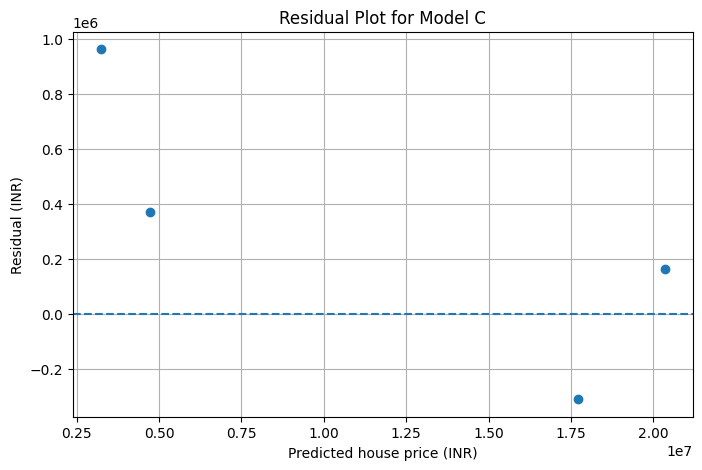

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted house price (INR)")
plt.ylabel("Residual (INR)")
plt.title("Residual Plot for Model C")
plt.grid(True)
plt.show()

The points should be checked for a pattern around the zero line. A fairly random spread is generally more suitable for a linear model than a clear curve or funnel shape. Since this is a small sample, the plot alone is not enough to make a strong conclusion.

## 7. Find the largest test errors

I sorted the test records by the absolute size of their residuals. This shows which test predictions were farthest from the actual prices.

In [11]:
residual_table["Absolute_Residual"] = residual_table["Residual"].abs()

largest_errors = residual_table.sort_values(
    by="Absolute_Residual", ascending=False
)

largest_errors.head(3)

,Actual_Price,Predicted_Price,Residual,Absolute_Residual
0,4200000,3.238447e+06,961552.940417,961552.940417
1,5100000,4.730145e+06,369854.517740,369854.517740
15,17400000,1.770959e+07,-309593.481503,309593.481503


The three rows above have the largest prediction errors in the test set. The residual sign shows whether the model predicted too low or too high. I would check the house details and, if possible, collect more information before deciding that any record should be removed.

## 8. Required questions

**1. How did Model B perform compared with Model A?**

Model B has a lower RMSE than Model A and a slightly higher R². However, its MAE is higher. So Model B did not improve every metric, even though it performed better on RMSE and R².

**2. Which features did you select for Model C? Why?**

I used area, age and distance for Model C. I kept area because the size of a house is useful for estimating its price. I also kept age and distance to check their contribution. I left out the bedroom count to compare a smaller feature set.

**3. Did adding all features improve test performance?**

Not on every metric. Model B has a higher MAE than Model A and Model C, although its RMSE and R² are better than Model A. A feature may not help much if it adds little useful information or overlaps with other features.

**4. What does a positive or negative residual mean?**

A positive residual means the actual price is higher than the predicted price, so the model predicted too low. A negative residual means the predicted price was higher than the actual price.

**5. What does the residual plot tell you?**

I look for points spread around the zero line without a clear curve or funnel shape. A visible pattern can mean that the model is missing something. Since there are only a few test records, I would be careful about drawing a strong conclusion from this plot.

**6. Which three test observations have the largest absolute residuals?**

The three records are displayed in the largest-errors table above. They are the test observations with the biggest differences between actual and predicted prices. Their feature values can be checked to understand why the predictions were less accurate.

**7. Why should the test set not be used repeatedly for feature selection?**

The test set is meant to give a final check on data the model has not used during development. If I keep making choices based on its results, I may indirectly adjust the model to that test set. The final score may then give an overly positive idea of how the model works on new data.

**8. Does a higher R² always mean a model is suitable?**

No. R² tells how much of the variation in the target is explained by the model, but it does not show the size of each prediction error. I should also check MAE and RMSE and consider whether the model makes sense for the problem.

## 9. Common mistakes and how to avoid them

1. **Putting `price_inr` inside X:** This gives the model the answer as an input. I keep it separate as `y`.
2. **Training with test data:** This makes the evaluation unfair. I fit the model only with the training data.
3. **Using a different split for each model:** The comparison would not be fair, so I reuse the same split.
4. **Checking only R²:** I also check MAE and RMSE to understand the prediction errors.
5. **Calculating residual in the wrong order:** I use actual value minus predicted value.
6. **Assuming correlation proves cause:** A relationship between two columns does not prove that one causes the other.

## 10. What I learned

**1. What is multiple linear regression?**

It is a regression method that uses more than one input column to predict a value. In this exercise, the inputs are house details and the output is the house price.

**2. What is feature selection?**

It means choosing which columns should be given to the model. Using fewer useful columns can make a model easier to understand and may avoid adding information that does not help.

**3. What is a residual?**

A residual is the difference between the actual value and the predicted value. For example, if a house actually costs ₹50 lakh but the model predicts ₹48 lakh, the residual is positive ₹2 lakh.

**4. What did you learn from comparing the models?**

I learned that adding more columns does not guarantee that every evaluation score will improve. Comparing different feature combinations gives a better idea of which inputs are useful.

**5. What would you improve with a larger dataset?**

I would collect more house records and include other details such as location, property condition and facilities. I would also check the data carefully and test the model on more unseen records.

## Final check

- [ ] The dataset loads and has been inspected.
- [ ] One train/test split is used for all models.
- [ ] Three feature combinations are compared.
- [ ] MAE, MSE, RMSE and R² are calculated.
- [ ] Residuals and the residual plot are included.
- [ ] The largest test errors are inspected.
- [ ] The notebook runs from top to bottom.

**Note:** Run all cells before submitting and add your name and any observations you personally noticed while running the notebook.